## 1. Loading + Simple Statistics

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.stats import entropy

In [2]:
# Imports to start with
DATA_DIR = './GoGymiUpdated' # you might need to change the directory

math_results = pd.read_csv('{}/math_results.csv'.format(DATA_DIR))
essay_results = pd.read_csv('{}/essay_results.csv'.format(DATA_DIR))

# math_results.head()
essay_results.head()
essay_results.columns

Index(['Unnamed: 0', 'user_id', 'course', 'textType', 'time', 'text',
       'content-on_topic', 'content-plausible', 'content-convincing_ideas',
       'content-scope', 'content-correct', 'structure-coherence',
       'structure-outline', 'structure-repetition', 'structure-text_pattern',
       'language-clarity', 'language-spelling', 'language-puncutation',
       'language-word_choice', 'language_sentence-structure',
       'language_style'],
      dtype='object')

In [3]:
distinct_math_users = math_results['user_id'].nunique()
distinct_essay_users = essay_results['user_id'].nunique()

print(f"Number of distinct users in math results: {distinct_math_users}")
print(f"Number of distinct users in essay results: {distinct_essay_users}")

Number of distinct users in math results: 599
Number of distinct users in essay results: 308


## 2. Feature Extraction
#### Mejia-Domenzain, Paola, et al. "Identifying and comparing multi-dimensional student profiles across flipped classrooms." International Conference on Artificial Intelligence in Education. Cham: Springer International Publishing, 2022.
### 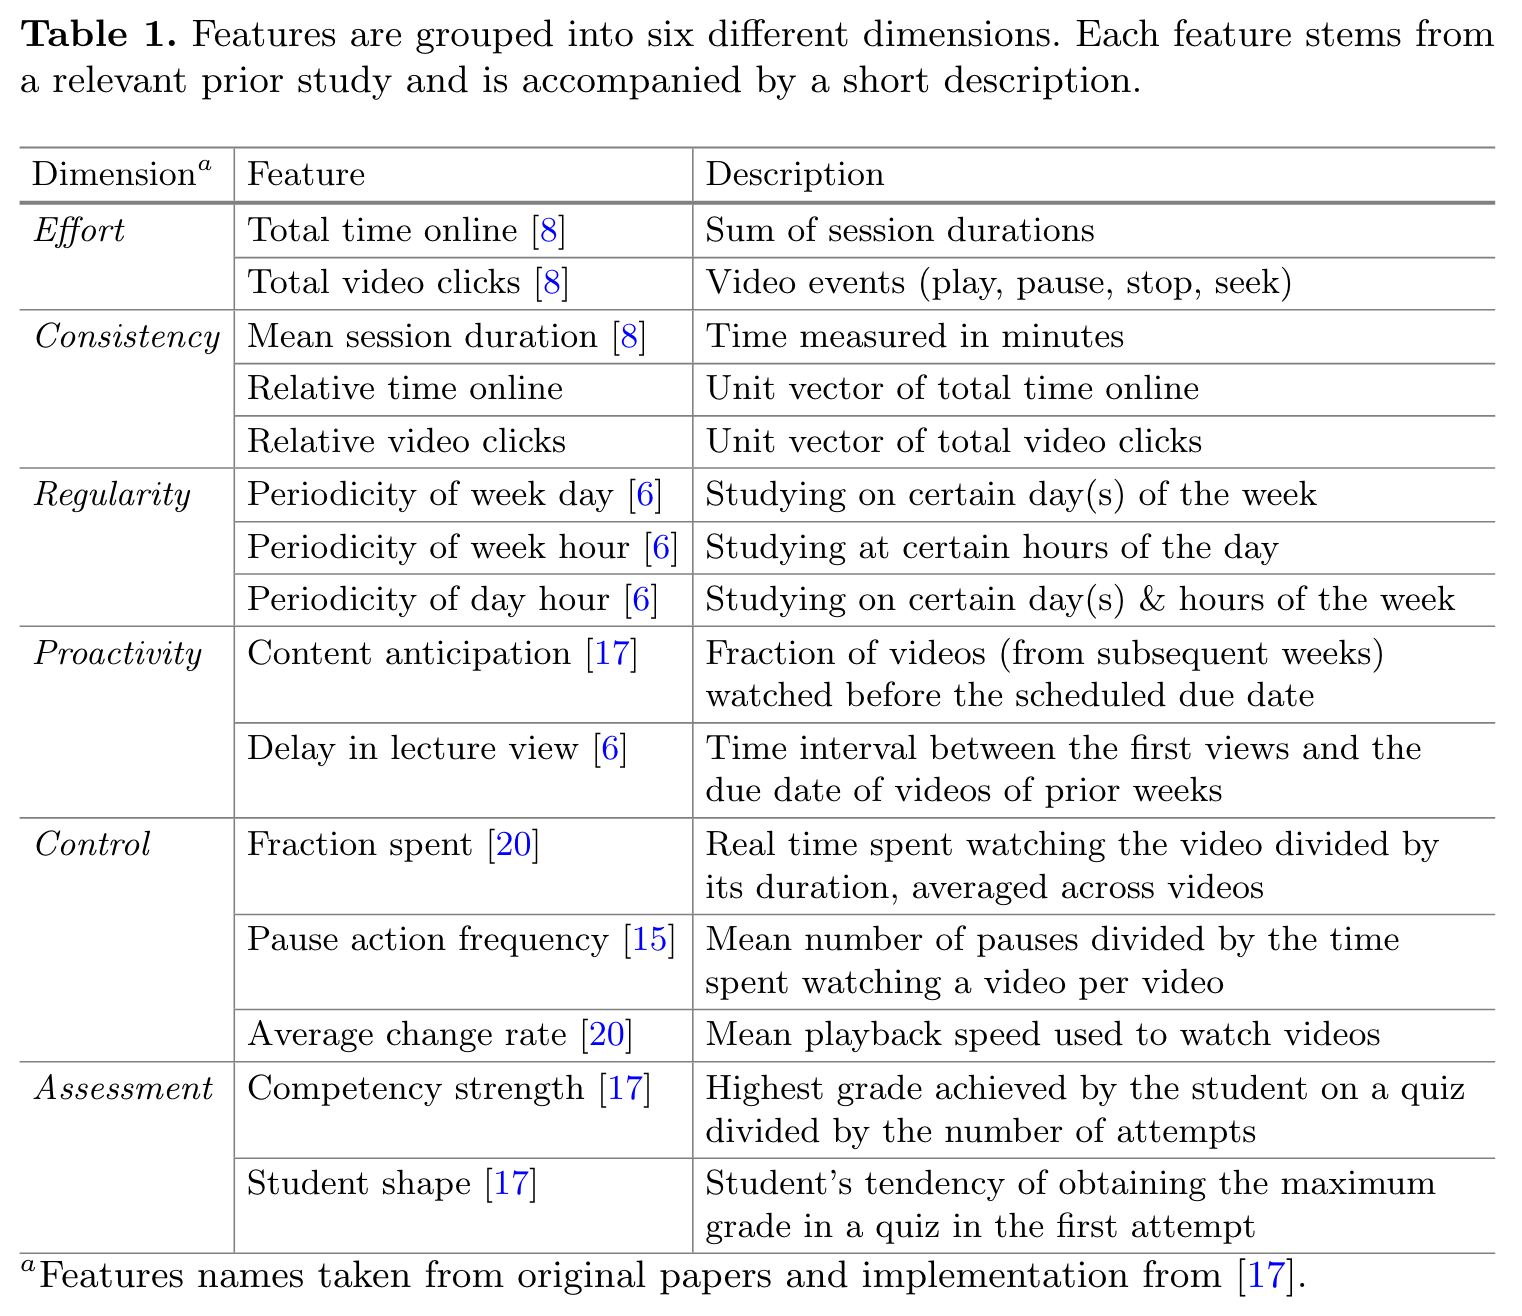

### 1) Effort: Total time online; Total video clicks

In [4]:
# Read activity.csv 
activity = pd.read_csv(
    '{}/activity.csv'.format(DATA_DIR),
    usecols=['user_id', 'activity_type', 'activity_status', 'activity_started', 'activity_completed'],
    dtype={'activity_status': int}  # Ensure status column is integer
)

# Convert Unix timestamps to datetime
activity['activity_started'] = pd.to_datetime(activity['activity_started'], unit='s', errors='coerce')
activity['activity_completed'] = pd.to_datetime(activity['activity_completed'], unit='s', errors='coerce')

# Filter valid sessions (status=1 and completion time is valid)
valid_activity = activity[
    (activity['activity_status'] == 1) &
    (~activity['activity_completed'].isna())
]

# Calculate average session duration (excluding access type)
non_access = valid_activity[valid_activity['activity_type'] != 'access']

def calculate_duration_stats(df):
    df = df.dropna(subset=['activity_started', 'activity_completed'])
    df['duration'] = (df['activity_completed'] - df['activity_started']).dt.total_seconds() / 3600
    return df.groupby('user_id')['duration'].agg(['sum', 'mean']).reset_index()

non_access_stats = calculate_duration_stats(non_access)
non_access_stats.columns = ['user_id', 'total_time_online', 'mean_session_duration']

# Calculate total access count 
access_counts = activity[
    (activity['activity_type'] == 'access')
].groupby('user_id').size().reset_index(name='total_access_counts')

# Merge results
result = pd.merge(non_access_stats, access_counts, on='user_id', how='left').fillna(0)

# Count users with zero learning time
zero_time_users = result[result['total_time_online'] == 0]
zero_time_users_count = len(zero_time_users)

# Print the count of users with zero learning time
print(f"Number of users with zero learning time: {zero_time_users_count}")

# Remove users with zero learning time
filtered_result = result[result['total_time_online'] > 0]

# Print basic statistics of filtered data
print(f"\nBasic statistics after removing users with zero learning time:")
print(f"Original number of users: {len(result)}")
print(f"Number of users after filtering: {len(filtered_result)}")
print(f"Percentage of users removed: {(zero_time_users_count / len(result) * 100):.2f}%")

# Print the first few rows of filtered data
print("\nFirst 5 rows of filtered data:")
print(filtered_result.head())

# Summary statistics of filtered data
print("\nSummary statistics of filtered data:")
print(filtered_result.describe())

Number of users with zero learning time: 5

Basic statistics after removing users with zero learning time:
Original number of users: 869
Number of users after filtering: 864
Percentage of users removed: 0.58%

First 5 rows of filtered data:
   user_id  total_time_online  mean_session_duration  total_access_counts
0        1       11965.677500             234.621127                  0.0
1        4         936.330000              24.008462                  1.0
2        6       35422.993889             398.011167                  0.0
3        7        4268.141389              76.216811                  0.0
4        9        7262.052500             177.123232                  1.0

Summary statistics of filtered data:
           user_id  total_time_online  mean_session_duration  \
count   864.000000         864.000000             864.000000   
mean   2011.615741       10503.292638             158.882513   
std    1591.244789       20182.578182             245.056551   
min       1.000000   

In [5]:
# Ensure total_time_online is numeric and has no missing values
result['total_time_online'] = pd.to_numeric(result['total_time_online'], errors='coerce')
result = result.dropna(subset=['total_time_online'])

# Standardize
scaler = StandardScaler()
# Extract standardized values and flatten to 1D array
relative_time_online = scaler.fit_transform(result[['total_time_online']]).flatten()
result['relative_time_online'] = relative_time_online

print("\nData after adding relative online time:")
print(result[['user_id', 'relative_time_online']].head())


Data after adding relative online time:
   user_id  relative_time_online
0        1              0.075655
1        4             -0.472293
2        6              1.241035
3        7             -0.306765
4        9             -0.158025


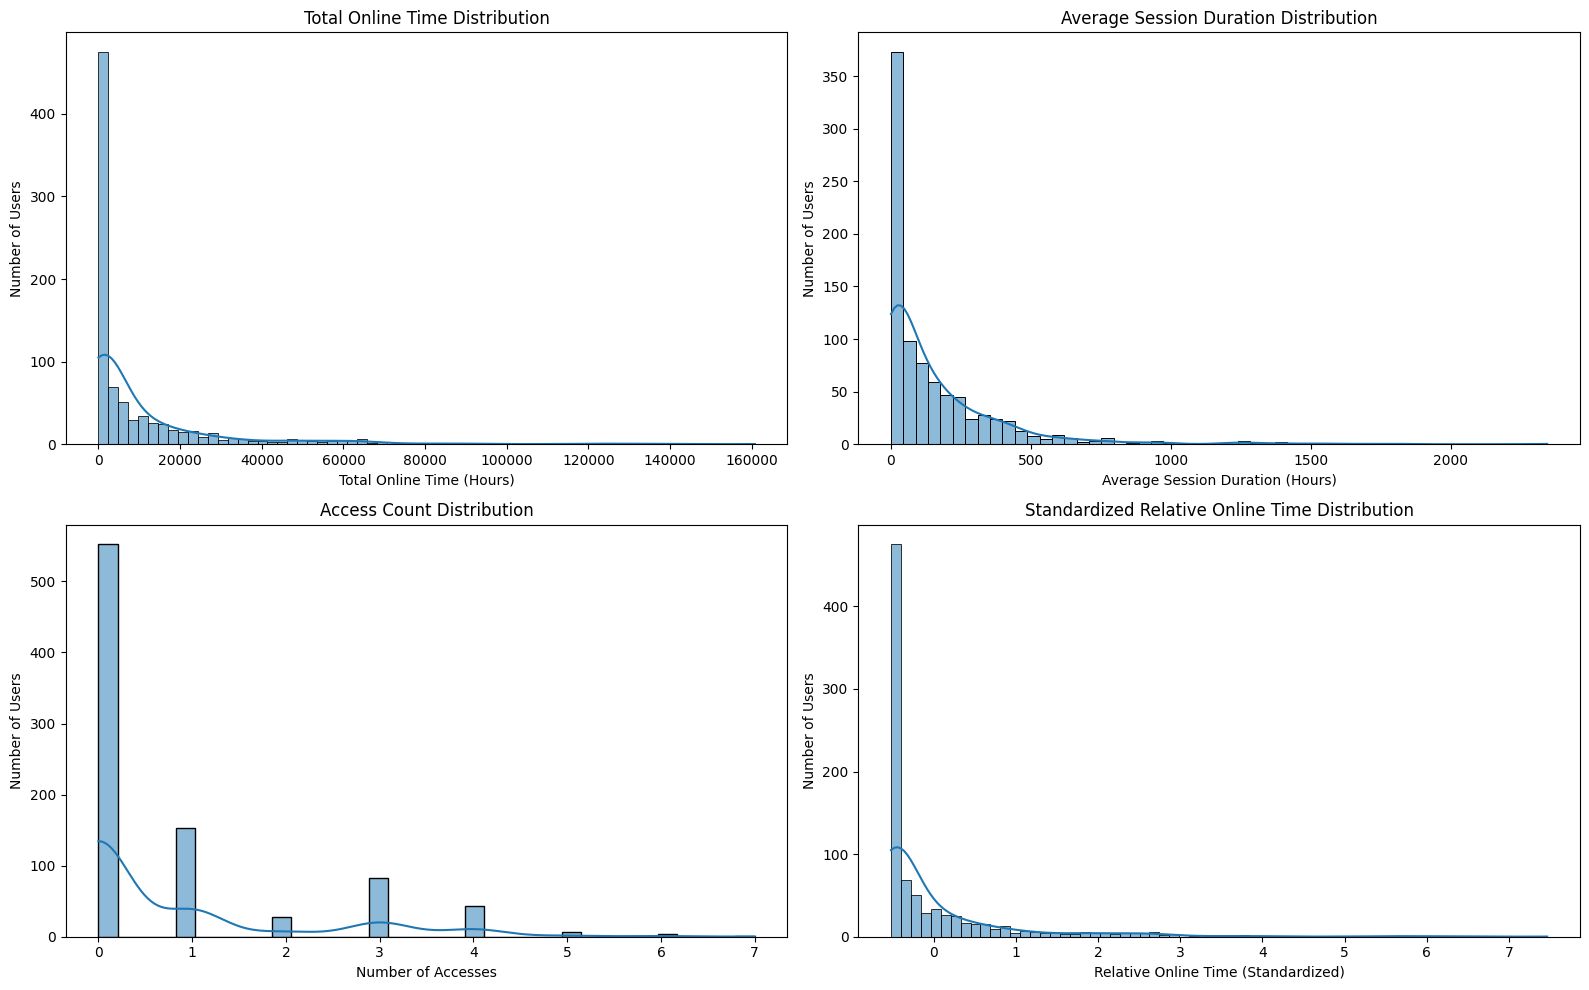

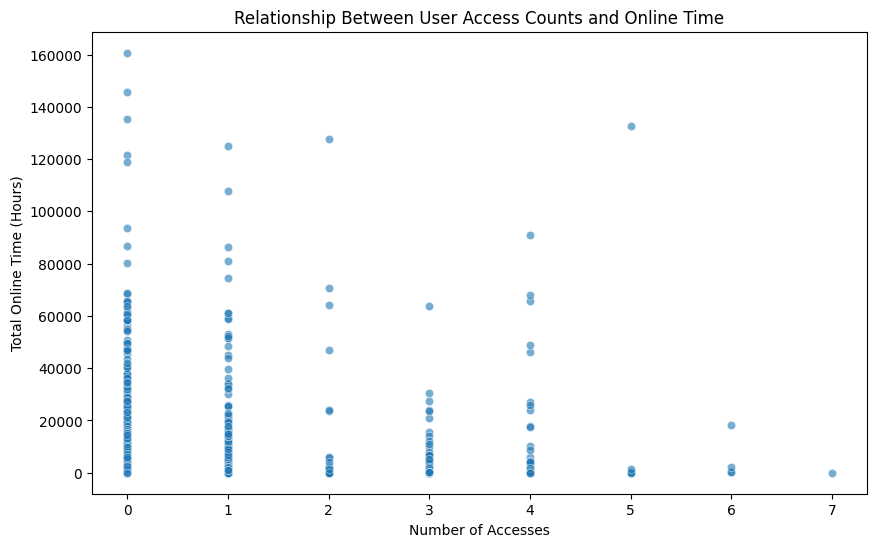

In [6]:
# Visualize data
plt.figure(figsize=(16, 10))

# 1. Total online time distribution
plt.subplot(2, 2, 1)
sns.histplot(result['total_time_online'], kde=True)
plt.title('Total Online Time Distribution')
plt.xlabel('Total Online Time (Hours)')
plt.ylabel('Number of Users')

# 2. Average session duration distribution
plt.subplot(2, 2, 2)
sns.histplot(result['mean_session_duration'], kde=True)
plt.title('Average Session Duration Distribution')
plt.xlabel('Average Session Duration (Hours)')
plt.ylabel('Number of Users')

# 3. Access count distribution
plt.subplot(2, 2, 3)
sns.histplot(result['total_access_counts'], kde=True)
plt.title('Access Count Distribution')
plt.xlabel('Number of Accesses')
plt.ylabel('Number of Users')

# 4. Relative online time distribution
plt.subplot(2, 2, 4)
sns.histplot(result['relative_time_online'], kde=True)
plt.title('Standardized Relative Online Time Distribution')
plt.xlabel('Relative Online Time (Standardized)')
plt.ylabel('Number of Users')

plt.tight_layout()
plt.show()

# Scatter plot: Relationship between access counts and online time
plt.figure(figsize=(10, 6))
sns.scatterplot(x='total_access_counts', y='total_time_online', data=result, alpha=0.6)
plt.title('Relationship Between User Access Counts and Online Time')
plt.xlabel('Number of Accesses')
plt.ylabel('Total Online Time (Hours)')
plt.show()


### 2）Regularity：Periodicity of week day/hour
#### Distribution of Weekday Regularity: the smaller the standard deviation (closer to 0), the more fixed the number of study days per week and the stronger the regularity.
#### Distribution of Joint Regularity:Low coefficient of variation (close to 0) represents that users’ learning behavior on fixed days and hours is highly stable (e.g., learning is required at 6pm every Monday and Wednesday).
#### Activity Distribution by Day of Week: shows the total amount of user activity per day in a week
#### Activity Heatmap by Weekday and Hour: this heat map uses color depth to show the user's activity level at different days and hours of the week.

In [7]:
# still based on activity
valid_activity = valid_activity.copy()

valid_activity['iso_year'] = valid_activity['activity_started'].dt.isocalendar().year
valid_activity['iso_week'] = valid_activity['activity_started'].dt.isocalendar().week
valid_activity['weekday'] = valid_activity['activity_started'].dt.day_name()
valid_activity['hour'] = valid_activity['activity_started'].dt.hour


In [8]:
# Count active days per week for each user
weekly_days = valid_activity.groupby(['user_id', 'iso_year', 'iso_week'])['weekday'].nunique().reset_index()
weekly_days.rename(columns={'weekday': 'active_days_per_week'}, inplace=True)

# Calculate standard deviation of active days per week (measure of regularity)
regularity_weekday = weekly_days.groupby('user_id')['active_days_per_week'].std().reset_index()
regularity_weekday.rename(columns={'active_days_per_week': 'regularity_weekday'}, inplace=True)

# Count activity hours distribution for each user
hourly_counts = valid_activity.groupby(['user_id', 'hour']).size().reset_index(name='hourly_activity')

# Calculate hour distribution entropy (lower entropy means higher regularity)
def calculate_hour_entropy(group):
    prob = group['hourly_activity'] / group['hourly_activity'].sum()
    return entropy(prob, base=2)

# Fix the warning by using group.agg() instead of apply
regularity_hour = hourly_counts.groupby('user_id').apply(
    lambda group: calculate_hour_entropy(group), 
    include_groups=False
).reset_index(name='regularity_hour')

# Count user activity on specific days and hours
joint_counts = valid_activity.groupby(['user_id', 'weekday', 'hour']).size().reset_index(name='joint_activity')

# Calculate joint distribution regularity (e.g., coefficient of variation)
def calculate_joint_regularity(group):
    mean = group['joint_activity'].mean()
    std = group['joint_activity'].std()
    return std / mean if mean != 0 else np.nan

# Fix the warning by using include_groups=False
regularity_joint = joint_counts.groupby('user_id').apply(
    lambda group: calculate_joint_regularity(group),
    include_groups=False
).reset_index(name='regularity_joint')

# Merge all metrics
regularity_metrics = pd.merge(regularity_weekday, regularity_hour, on='user_id', how='left')
regularity_metrics = pd.merge(regularity_metrics, regularity_joint, on='user_id', how='left')

# Output results
print("Regularity Metrics (First 5 rows):")
print(regularity_metrics.head())

Regularity Metrics (First 5 rows):
   user_id  regularity_weekday  regularity_hour  regularity_joint
0        1            1.012739         3.895068          0.782920
1        4            0.487950         1.970599          0.815892
2        6            1.166667         3.332794          0.730717
3        7            0.834847         3.053428          0.722315
4        9            0.487950         2.129275          1.232552


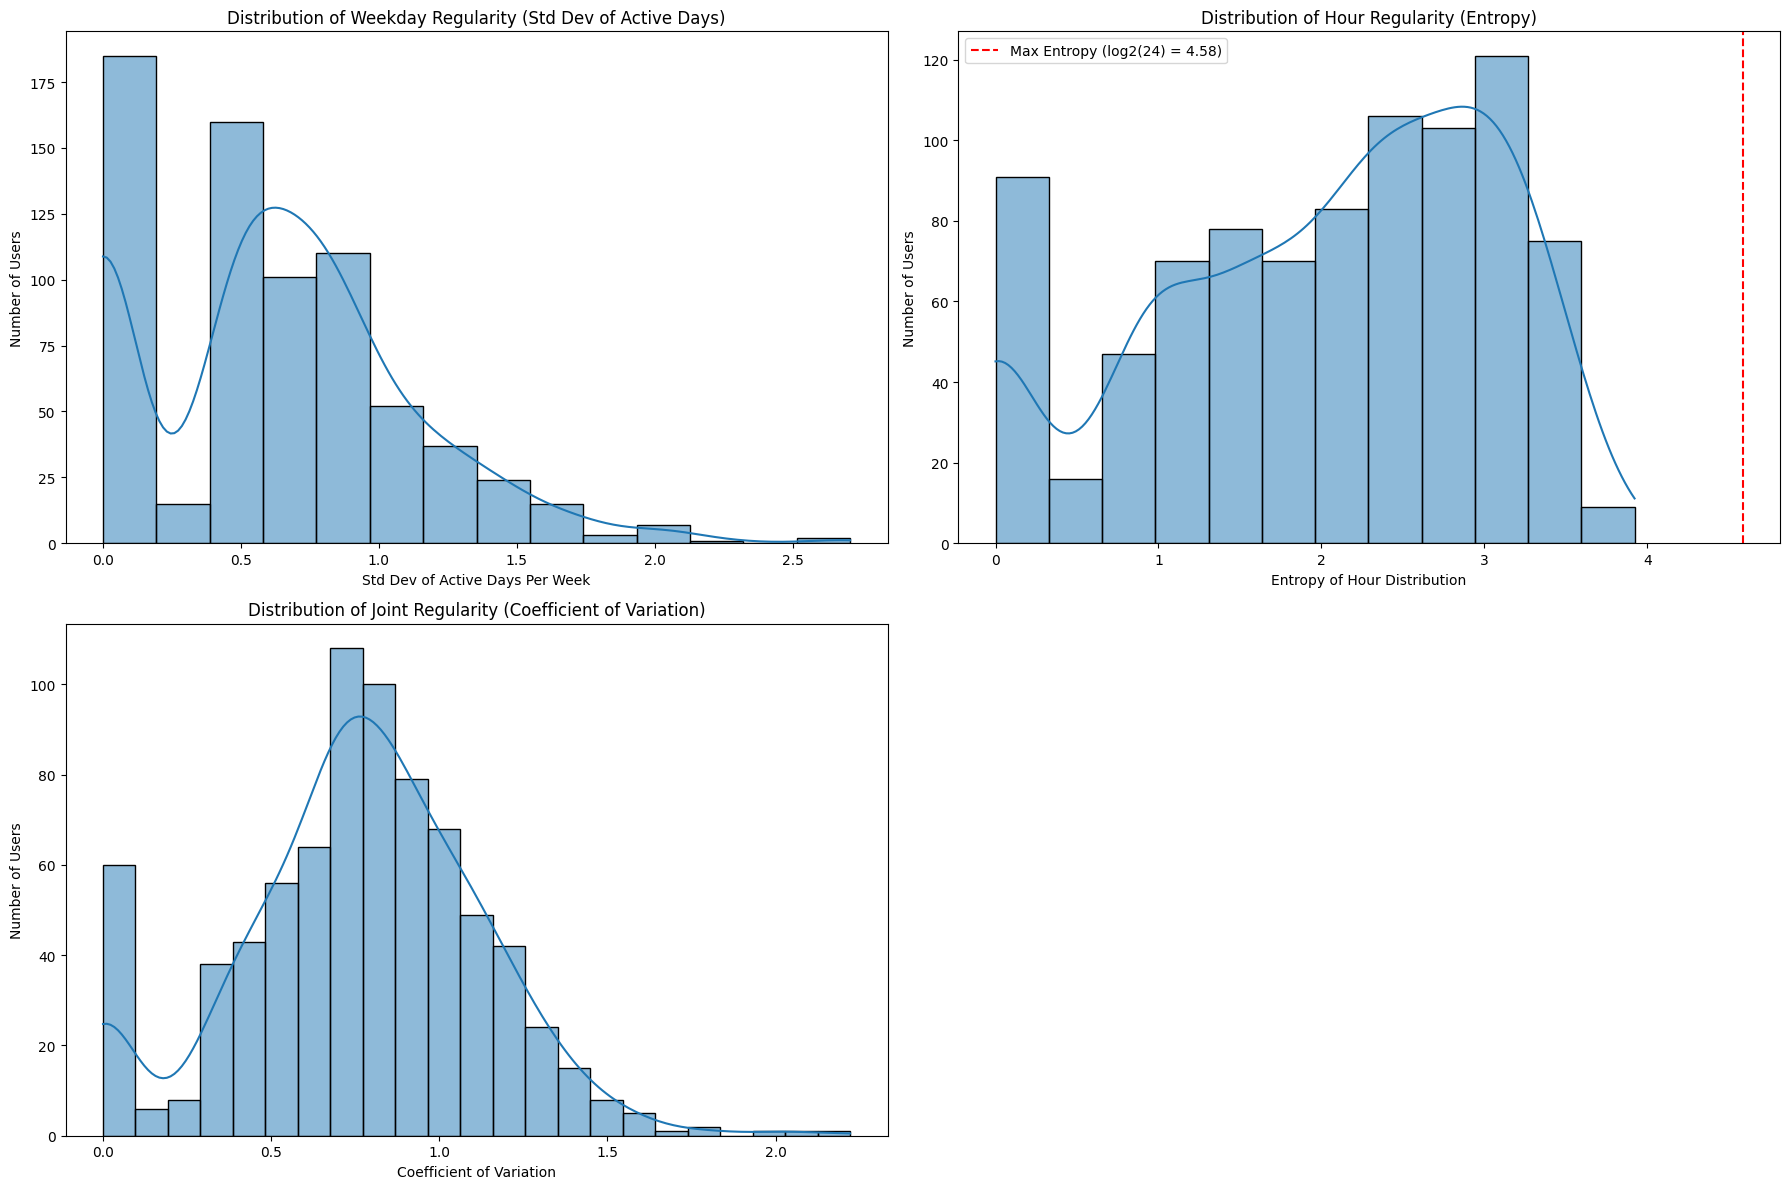

In [9]:
# Visualizations for regularity metrics
plt.figure(figsize=(18, 12))

# 1. Distribution of weekday regularity
plt.subplot(2, 2, 1)
sns.histplot(regularity_metrics['regularity_weekday'].dropna(), kde=True)
plt.title('Distribution of Weekday Regularity (Std Dev of Active Days)')
plt.xlabel('Std Dev of Active Days Per Week')
plt.ylabel('Number of Users')

# 2. Distribution of hour regularity (entropy)
plt.subplot(2, 2, 2)
sns.histplot(regularity_metrics['regularity_hour'].dropna(), kde=True)
plt.title('Distribution of Hour Regularity (Entropy)')
plt.xlabel('Entropy of Hour Distribution')
plt.ylabel('Number of Users')
plt.axvline(x=np.log2(24), color='r', linestyle='--', 
            label=f'Max Entropy (log2(24) = {np.log2(24):.2f})')
plt.legend()

# 3. Distribution of joint regularity (coefficient of variation)
plt.subplot(2, 2, 3)
sns.histplot(regularity_metrics['regularity_joint'].dropna(), kde=True)
plt.title('Distribution of Joint Regularity (Coefficient of Variation)')
plt.xlabel('Coefficient of Variation')
plt.ylabel('Number of Users')

plt.tight_layout()
plt.show()

### Analysis: 
##### 1. The standard deviation of most users is concentrated below 1, indicating that most users study on a relatively fixed number of days per week.
##### 2. The Distribution of hour regularity has a high entropy value, indicating that learning time is scattered throughout the day.
##### 3. The coefficient of variation for most users is less than 1, indicating that the study time of most users has obvious regularity in specific combinations (such as “10 a.m. on Monday”).

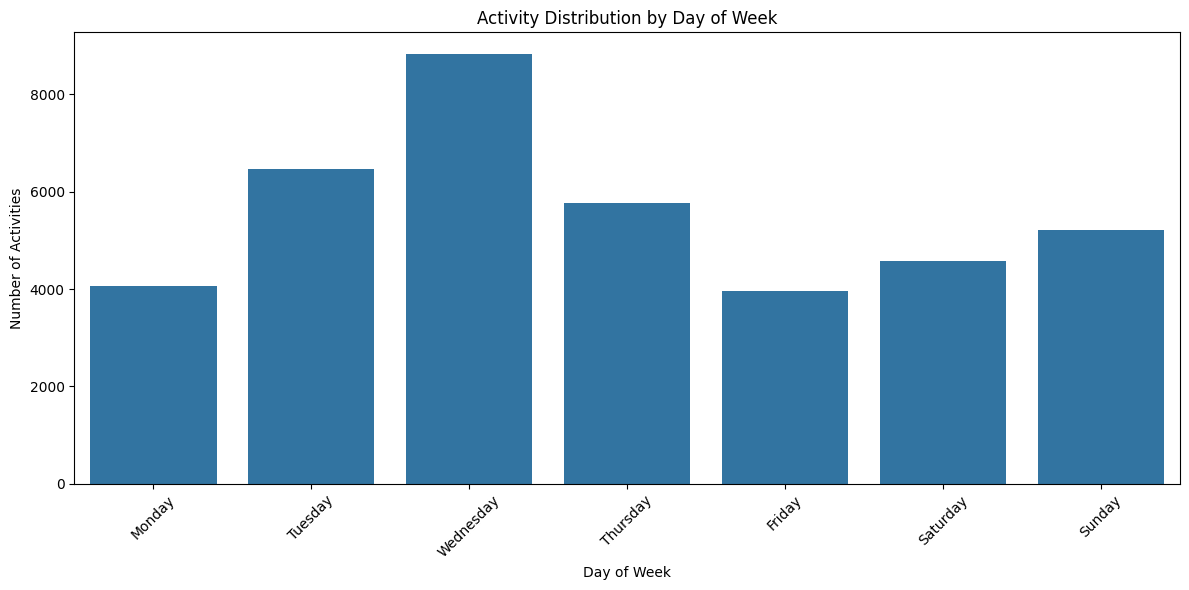

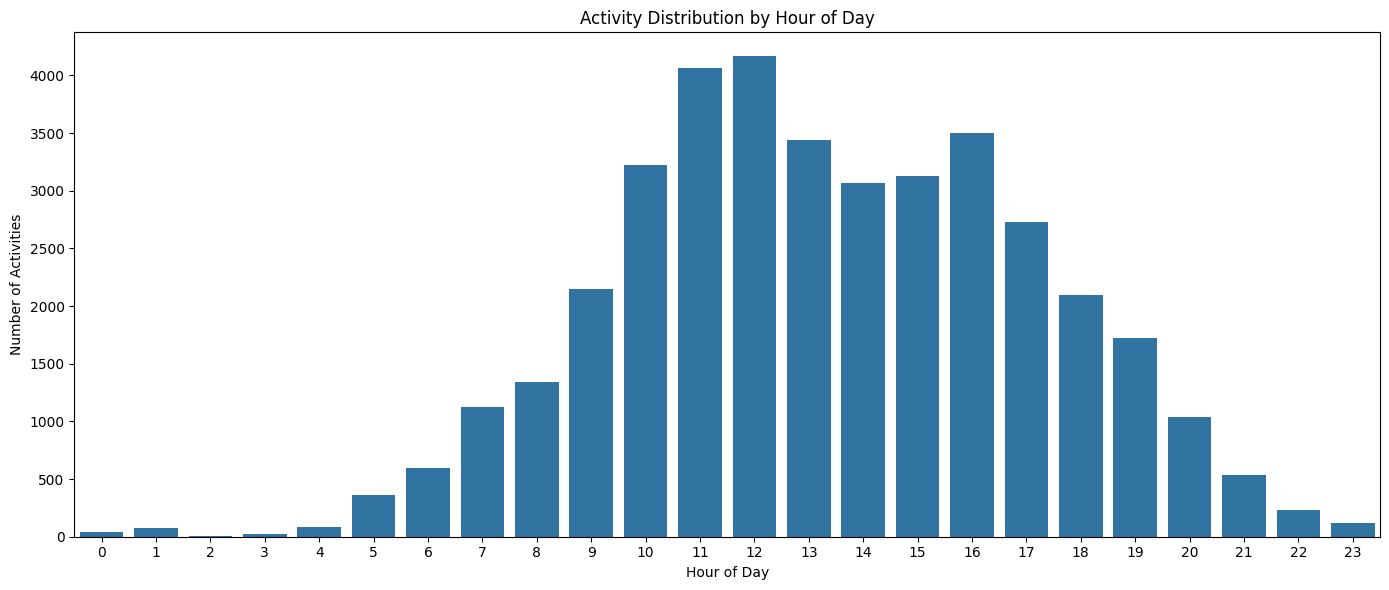

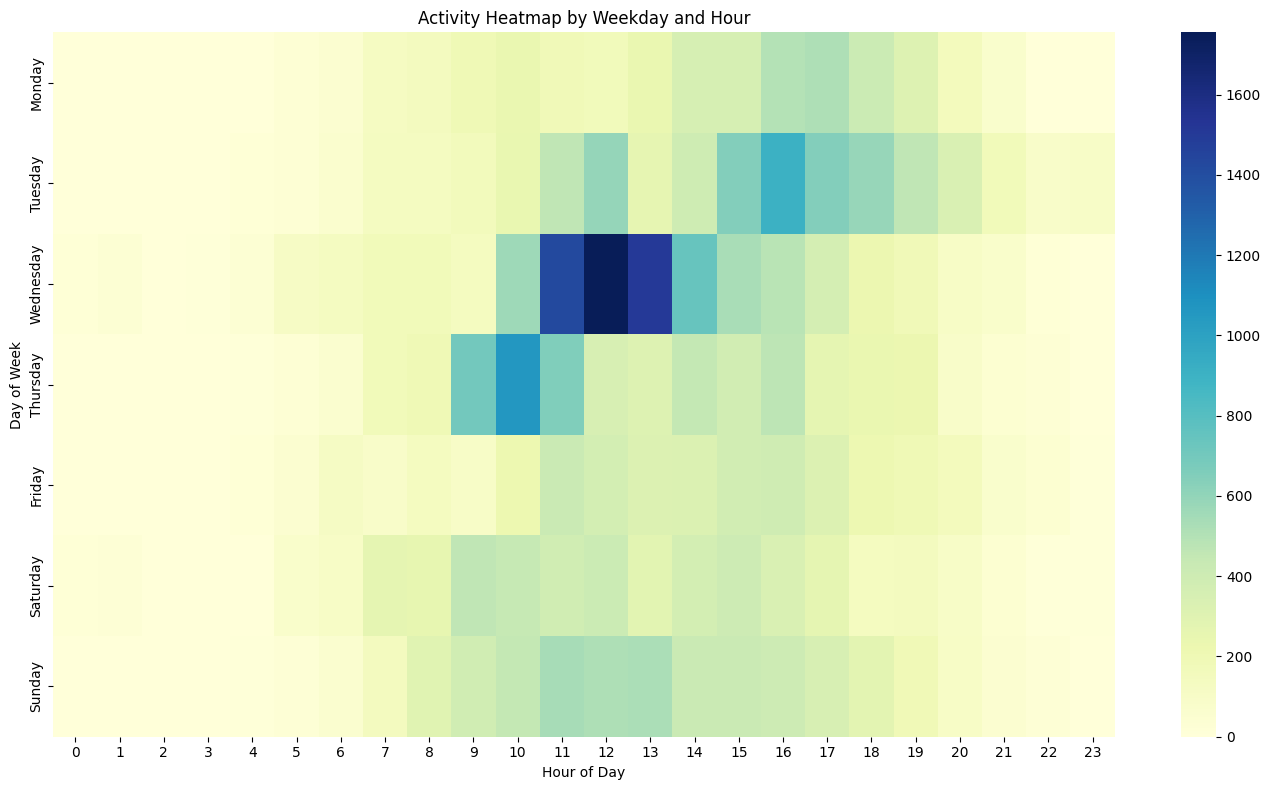

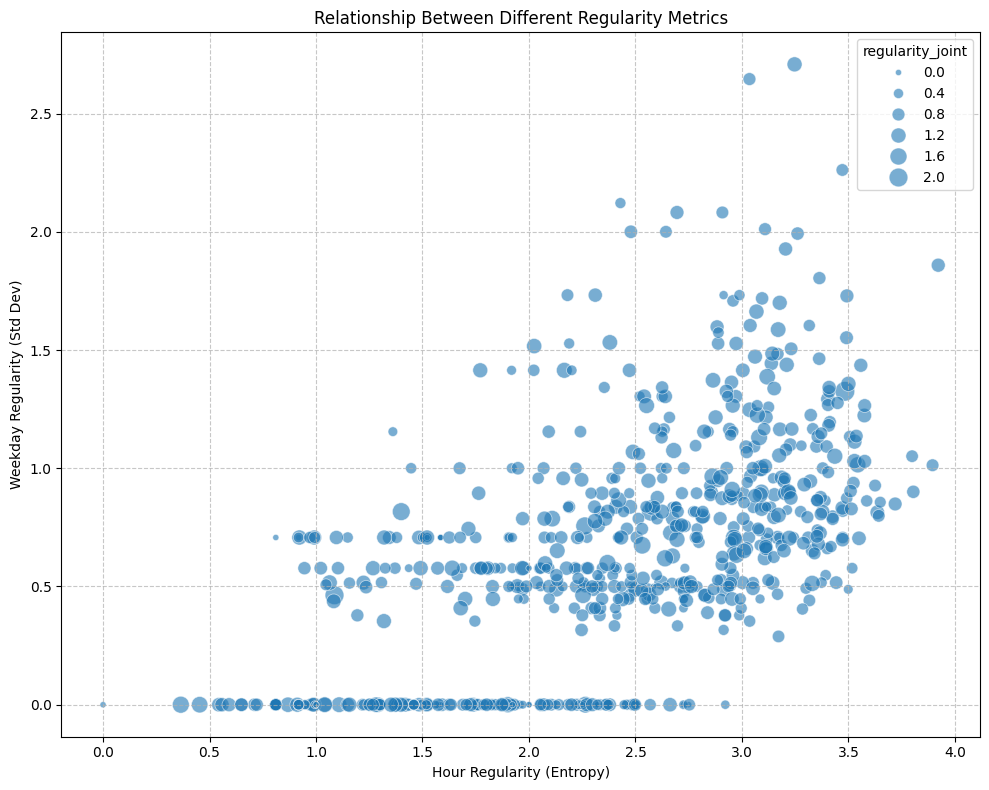

In [10]:
# Visualize activity patterns

# 1. Weekly activity pattern
plt.figure(figsize=(12, 6))
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekly_pattern = valid_activity.groupby('weekday').size()
weekly_pattern = weekly_pattern.reindex(weekday_order)

sns.barplot(x=weekly_pattern.index, y=weekly_pattern.values)
plt.title('Activity Distribution by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Activities')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Hourly activity pattern
plt.figure(figsize=(14, 6))
hourly_pattern = valid_activity.groupby('hour').size()
sns.barplot(x=hourly_pattern.index, y=hourly_pattern.values)
plt.title('Activity Distribution by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Activities')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

# 3. Heatmap of joint weekday-hour activity
plt.figure(figsize=(14, 8))
joint_pattern = valid_activity.groupby(['weekday', 'hour']).size().unstack(fill_value=0)
joint_pattern = joint_pattern.reindex(weekday_order)
sns.heatmap(joint_pattern, cmap='YlGnBu', annot=False, fmt='.0f')
plt.title('Activity Heatmap by Weekday and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.show()

# 4. Scatter plot comparing regularity metrics
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='regularity_hour', 
    y='regularity_weekday', 
    size='regularity_joint',
    sizes=(20, 200),
    alpha=0.6,
    data=regularity_metrics.dropna()
)
plt.title('Relationship Between Different Regularity Metrics')
plt.xlabel('Hour Regularity (Entropy)')
plt.ylabel('Weekday Regularity (Std Dev)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 3） Assessment：Competency strength，Student shape

In [24]:
# math part
# 1. Calculate score ratio for each attempt
attempt_scores = math_results.groupby(
    ["session_id", "user_id", "course_id", "exam_id"]
).agg(
    sum_points=("points", "sum"),
    sum_max_points=("max_points", "sum"),
    timestamp=("time", "min")  # Added timestamp to identify first attempt
).reset_index()

# Handle division by zero
attempt_scores["total_score_ratio"] = (
    attempt_scores["sum_points"] / attempt_scores["sum_max_points"].replace(0, 1)
).fillna(0)

# 2. Group by user and exam, calculate maximum score ratio and number of attempts
competency_strength = attempt_scores.groupby(
    ["user_id", "course_id", "exam_id"]
).agg(
    max_score_ratio=("total_score_ratio", "max"),
    attempts=("session_id", "count")
).reset_index()

# 3. Calculate competency strength
competency_strength["competency_strength"] = (
    competency_strength["max_score_ratio"] / competency_strength["attempts"]
)

# sort attempts by timestamp for each user-exam combination
user_exam_attempts = attempt_scores.sort_values(
    ["user_id", "course_id", "exam_id", "timestamp"]
)

# Process each user-exam combination
max_score_analysis = []

for (user_id, course_id, exam_id), group in user_exam_attempts.groupby(["user_id", "course_id", "exam_id"]):
    group = group.sort_values("timestamp")  # Ensure chronological order
    max_score = group["total_score_ratio"].max()
    first_attempt_score = group["total_score_ratio"].iloc[0]
    max_on_first_attempt = (first_attempt_score == max_score) and (max_score > 0)
    
    max_score_analysis.append({
        "user_id": user_id,
        "course_id": course_id,
        "exam_id": exam_id,
        "max_score": max_score,
        "first_attempt_score": first_attempt_score,
        "max_on_first_attempt": max_on_first_attempt,
        "total_attempts": len(group)
    })

max_score_df = pd.DataFrame(max_score_analysis)

# Calculate the tendency (Shape 17)
max_on_first_attempt_rate = max_score_df["max_on_first_attempt"].mean()

# --- Output Results ---
print("Competency Strength Analysis (First 5 rows):")
print(competency_strength.head())

print("\nStudent Shape [17]: Student's tendency of obtaining the maximum grade in a quiz in the first attempt:")
print(f"Rate: {max_on_first_attempt_rate:.4f}")
print("\nDetailed Max Score Analysis (First 5 rows):")
print(max_score_df.head())

# Merge the two analyses for a comprehensive view
combined_analysis = competency_strength.merge(
    max_score_df[["user_id", "course_id", "exam_id", "max_on_first_attempt"]],
    on=["user_id", "course_id", "exam_id"],
    how="left"
)

print("\nCombined Analysis (First 5 rows):")
print(combined_analysis.head())

Competency Strength Analysis (First 5 rows):
   user_id  course_id  exam_id  max_score_ratio  attempts  competency_strength
0        1       3301       64         0.615385         1             0.615385
1        1       3865       66         0.000000         2             0.000000
2        6       3301       64         0.615385         1             0.615385
3        6       3865       42         1.000000         6             0.166667
4        6       3865       48         0.500000         1             0.500000

Student Shape [17]: Student's tendency of obtaining the maximum grade in a quiz in the first attempt:
Rate: 0.7200

Detailed Max Score Analysis (First 5 rows):
   user_id  course_id  exam_id  max_score  first_attempt_score  \
0        1       3301       64   0.615385             0.615385   
1        1       3865       66   0.000000             0.000000   
2        6       3301       64   0.615385             0.615385   
3        6       3865       42   1.000000             0.

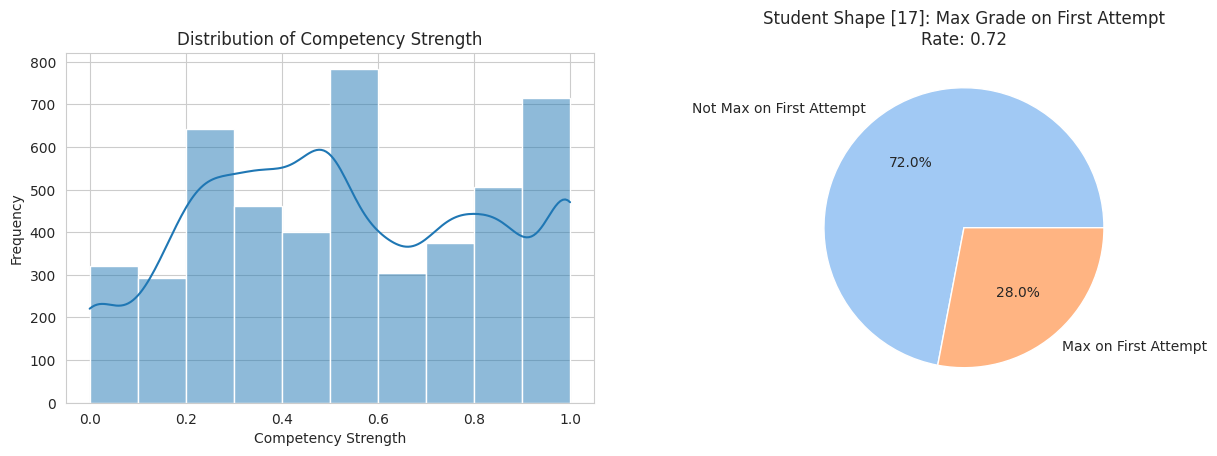

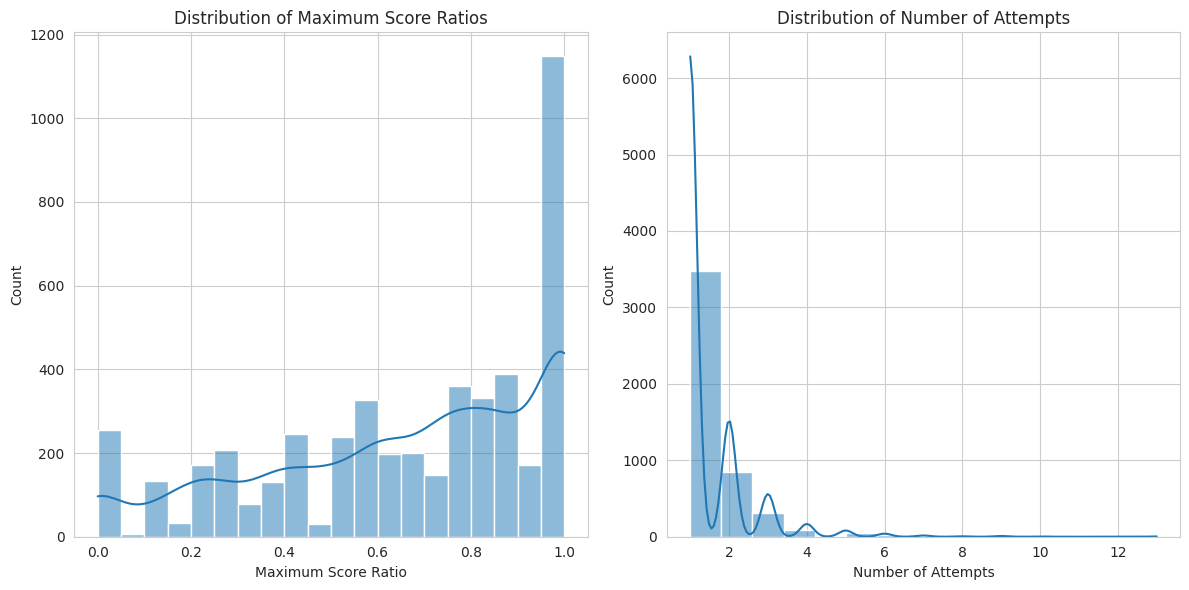

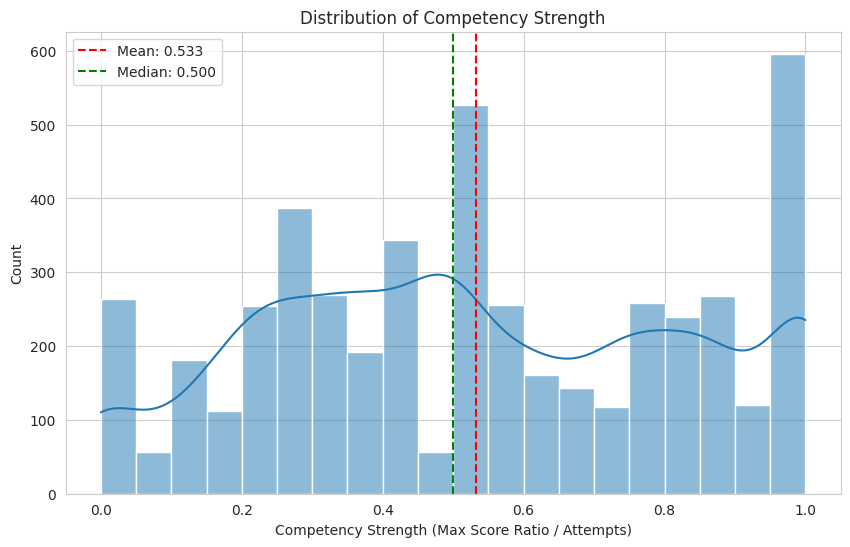

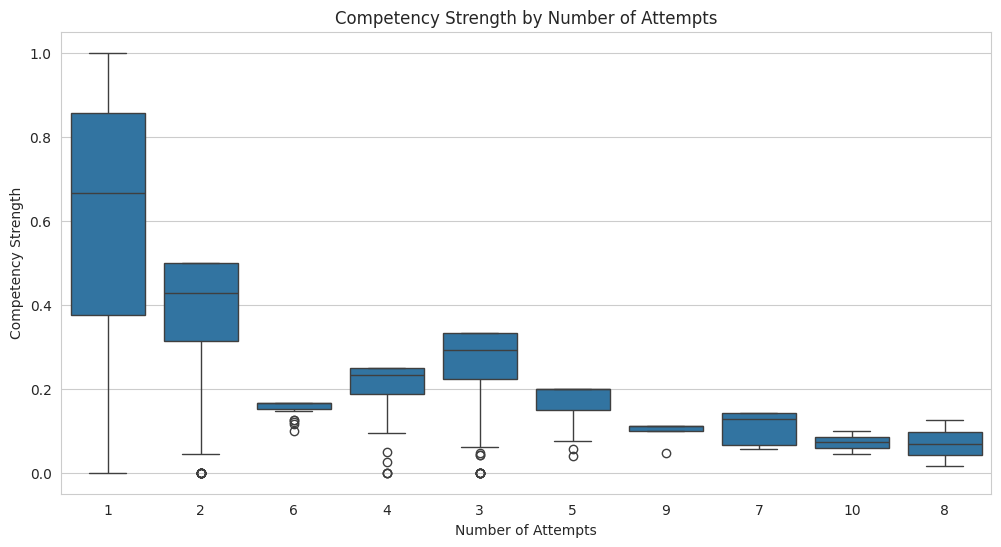

ValueError: Unable to determine Axes to steal space for Colorbar. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.

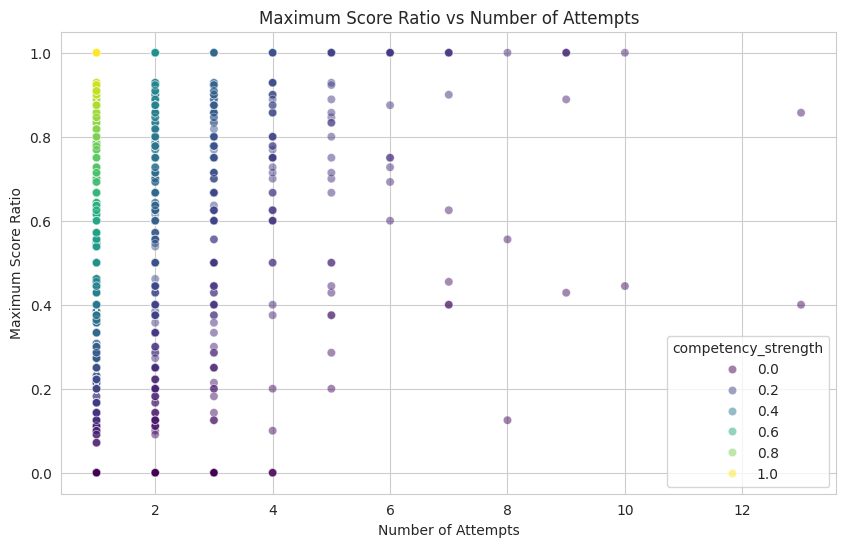

In [26]:
# Visualizations
plt.figure(figsize=(15, 10))

# Set the style for the plots
sns.set_style("whitegrid")

# 1. Visualization for Competency Strength
plt.subplot(2, 2, 1)
sns.histplot(competency_strength["competency_strength"], kde=True, bins=10)
plt.title("Distribution of Competency Strength")
plt.xlabel("Competency Strength")
plt.ylabel("Frequency")

# 2. Visualization for Maximum Score on First Attempt (Shape 17)
plt.subplot(2, 2, 2)
max_first_attempt_counts = max_score_df["max_on_first_attempt"].value_counts()
plt.pie(max_first_attempt_counts, 
        labels=["Not Max on First Attempt", "Max on First Attempt"] if False in max_first_attempt_counts.index else ["Max on First Attempt"],
        autopct='%1.1f%%',
        colors=sns.color_palette("pastel"))
plt.title(f"Student Shape [17]: Max Grade on First Attempt\nRate: {max_on_first_attempt_rate:.2f}")

# 1. Distribution of maximum score ratios
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(competency_strength["max_score_ratio"], kde=True, bins=20)
plt.title("Distribution of Maximum Score Ratios")
plt.xlabel("Maximum Score Ratio")
plt.ylabel("Count")

# 2. Distribution of attempts
plt.subplot(1, 2, 2)
sns.histplot(competency_strength["attempts"], kde=True, bins=15)
plt.title("Distribution of Number of Attempts")
plt.xlabel("Number of Attempts")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

# 3. Distribution of competency strength
plt.figure(figsize=(10, 6))
sns.histplot(competency_strength["competency_strength"], kde=True, bins=20)
plt.title("Distribution of Competency Strength")
plt.xlabel("Competency Strength (Max Score Ratio / Attempts)")
plt.ylabel("Count")
plt.axvline(competency_strength["competency_strength"].mean(), color='r', linestyle='--', 
            label=f'Mean: {competency_strength["competency_strength"].mean():.3f}')
plt.axvline(competency_strength["competency_strength"].median(), color='g', linestyle='--', 
            label=f'Median: {competency_strength["competency_strength"].median():.3f}')
plt.legend()
plt.show()

# 5. Boxplot of competency strength by attempt count
plt.figure(figsize=(12, 6))
# Limit to users with reasonable number of attempts for better visualization
plot_data = competency_strength[competency_strength["attempts"] <= 10].copy()
# Group attempts for clearer visualization
plot_data["attempt_group"] = plot_data["attempts"].astype(str)
sns.boxplot(x="attempt_group", y="competency_strength", data=plot_data)
plt.title("Competency Strength by Number of Attempts")
plt.xlabel("Number of Attempts")
plt.ylabel("Competency Strength")
plt.show()

# 4. Scatter plot of max score ratio vs attempts
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="attempts", 
    y="max_score_ratio", 
    data=competency_strength, 
    alpha=0.5,
    hue="competency_strength",
    palette="viridis"
)
plt.title("Maximum Score Ratio vs Number of Attempts")
plt.xlabel("Number of Attempts")
plt.ylabel("Maximum Score Ratio")
plt.colorbar(plt.cm.ScalarMappable(cmap="viridis"), label="Competency Strength")
plt.show()

In [15]:
# essay part

def analyze_essay_scores(essay_path):
    # 1. Read the essay results data
    essay_results = pd.read_csv(essay_path)
    
    # 2. Define scoring weights
    weights = {
        'content-on_topic': 0.15,
        'content-plausible': 0.15,
        'content-convincing_ideas': 0.15,
        'content-scope': 0.1,
        'content-correct': 0.1,
        'structure-coherence': 0.1,
        'structure-outline': 0.05,
        'structure-repetition': 0.05,
        'structure-text_pattern': 0.05,
        'language-clarity': 0.05,
        'language-spelling': 0.025,
        'language-punctuation': 0.025,
        'language-word_choice': 0.025,
        'language_sentence-structure': 0.025,
        'language_style': 0.025
    }
    
    # 3. Check if all weight columns exist in the DataFrame
    missing_columns = [col for col in weights.keys() if col not in essay_results.columns]
    if missing_columns:
        print(f"Warning: The following columns are missing: {missing_columns}")
        print("Available columns:", essay_results.columns.tolist())
        # Create missing columns with default value 0
        for col in missing_columns:
            essay_results[col] = 0
    
    # 4. Fill missing values with 0 and ensure numeric types
    essay_results[list(weights.keys())] = essay_results[list(weights.keys())].fillna(0).astype(float)
    
    # 5. Calculate weighted total score
    essay_results['total_score'] = essay_results.apply(
        lambda row: sum(row[col] * weight for col, weight in weights.items()),
        axis=1
    )
    
    # 6. Group by user and course to get maximum scores
    max_scores = essay_results.groupby(
        ['user_id', 'course']
    )['total_score'].max().reset_index(name='max_total_score')
    
    # 7. Merge to get details of top essays
    top_essays = essay_results.merge(
        max_scores,
        on=['user_id', 'course'],
        how='inner',
        suffixes=('', '_max')
    )
    
    # 8. Filter to keep only rows where total_score equals max_total_score
    top_essays = top_essays[top_essays['total_score'] == top_essays['max_total_score']]
    
    # 9. Drop duplicates to keep only one entry per user per course
    top_essays = top_essays.drop_duplicates(subset=['user_id', 'course'])
    
    return max_scores, top_essays




Essay Maximum Scores Statistics:
   user_id  course  max_total_score
0        1    3301            5.400
1        1    5447            3.900
2        4    3301            6.200
3        5    5447            1.925
4        6    3301            6.775

Top Essay Details:
    user_id  course    textType  total_score
6      3255    5447  erzaehlung        6.550
15     3503    5447  erzaehlung        6.550
16     2439    5447  erzaehlung        6.225
18     3526    5447  erzaehlung        6.225
22     3254    5447  erzaehlung        6.425


In [30]:
#essay part
# Define scoring weights
weights = {
    'content-on_topic': 0.15,
    'content-plausible': 0.15,
    'content-convincing_ideas': 0.15,
    'content-scope': 0.1,
    'content-correct': 0.1,
    'structure-coherence': 0.1,
    'structure-outline': 0.05,
    'structure-repetition': 0.05,
    'structure-text_pattern': 0.05,
    'language-clarity': 0.05,
    'language-spelling': 0.025,
    'language-punctuation': 0.025,  # Corrected spelling
    'language-word_choice': 0.025,
    'language_sentence-structure': 0.025,
    'language_style': 0.025
}

print("Sum of weights:", sum(weights.values()))  # Confirm weight sum equals 1

# Check if all weight columns exist in the DataFrame
missing_columns = [col for col in weights if col not in essay_results.columns]
if missing_columns:
    print(f"Warning: The following columns are missing: {missing_columns}")
    print("Available columns:", essay_results.columns.tolist())
    # Create missing columns with default value 0
    for col in missing_columns:
        essay_results[col] = 0
        print(f"Created missing column '{col}' and filled with 0")

# Fill missing values with 0 and ensure numeric types
essay_results[list(weights.keys())] = essay_results[list(weights.keys())].fillna(0).astype(float)
print(f"Number of records after handling missing values: {len(essay_results)}")

# Calculate weighted total score
essay_results['total_score'] = essay_results.apply(
    lambda row: sum(row[col] * weight for col, weight in weights.items()),
    axis=1
)
print("Total scores for first 5 rows:")
print(essay_results[['user_id', 'course', 'total_score']].head())

# Calculate maximum possible score
max_possible_score = sum(weights.values()) * 10  # Assuming maximum score for each category is 10
print(f"Maximum possible score: {max_possible_score}")

# Calculate score as a percentage of maximum possible
essay_results['score_percentage'] = essay_results['total_score'] / max_possible_score
print("Percentage scores for first 5 rows:")
print(essay_results[['user_id', 'course', 'total_score', 'score_percentage']].head())

# Add timestamp information for chronological ordering
essay_results['timestamp'] = essay_results['time']
    
# Process each user-course combination to see if max score was achieved on first attempt
essay_max_score_analysis = []
for (user_id, course), group in essay_results.groupby(['user_id', 'course']):
    # Sort submissions by timestamp
    group = group.sort_values('timestamp')
    
    # Get max score and first attempt score
    max_score = group['score_percentage'].max()
    first_attempt_score = group['score_percentage'].iloc[0]
    
    # Check if max score was achieved on first attempt
    max_on_first_attempt = (first_attempt_score == max_score) and (max_score > 0)
    
    essay_max_score_analysis.append({
        'user_id': user_id,
        'course': course,
        'max_score': max_score,
        'first_attempt_score': first_attempt_score,
        'max_on_first_attempt': max_on_first_attempt,
        'total_attempts': len(group)
    })

essay_max_score_df = pd.DataFrame(essay_max_score_analysis)
print(f"Total user-course combinations: {len(essay_max_score_df)}")

# Calculate the tendency (Shape 17) for essays
essay_max_on_first_attempt_rate = essay_max_score_df['max_on_first_attempt'].mean()
print(f"Shape [17] Rate of max score on first attempt: {essay_max_on_first_attempt_rate:.4f}")
print(f"Number of users with max score on first attempt: {essay_max_score_df['max_on_first_attempt'].sum()}")
print(f"Total number of users: {len(essay_max_score_df)}")

# Additional statistics
print("\nBasic Statistics:")
print(f"Average maximum score: {essay_max_score_df['max_score'].mean():.4f}")
print(f"Average first attempt score: {essay_max_score_df['first_attempt_score'].mean():.4f}")
print(f"Average number of attempts: {essay_max_score_df['total_attempts'].mean():.2f}")


Sum of weights: 1.075
Number of records after handling missing values: 1985
Total scores for first 5 rows:
   user_id  course  total_score
0     3203    5447        6.225
1     3203    5447        6.375
2     3526    5447        5.475
3     3526    5447        3.600
4     3514    5447        5.500
Maximum possible score: 10.75
Percentage scores for first 5 rows:
   user_id  course  total_score  score_percentage
0     3203    5447        6.225          0.579070
1     3203    5447        6.375          0.593023
2     3526    5447        5.475          0.509302
3     3526    5447        3.600          0.334884
4     3514    5447        5.500          0.511628
Total user-course combinations: 364
Shape [17] Rate of max score on first attempt: 0.3956
Number of users with max score on first attempt: 144
Total number of users: 364

Basic Statistics:
Average maximum score: 0.5410
Average first attempt score: 0.4680
Average number of attempts: 5.45


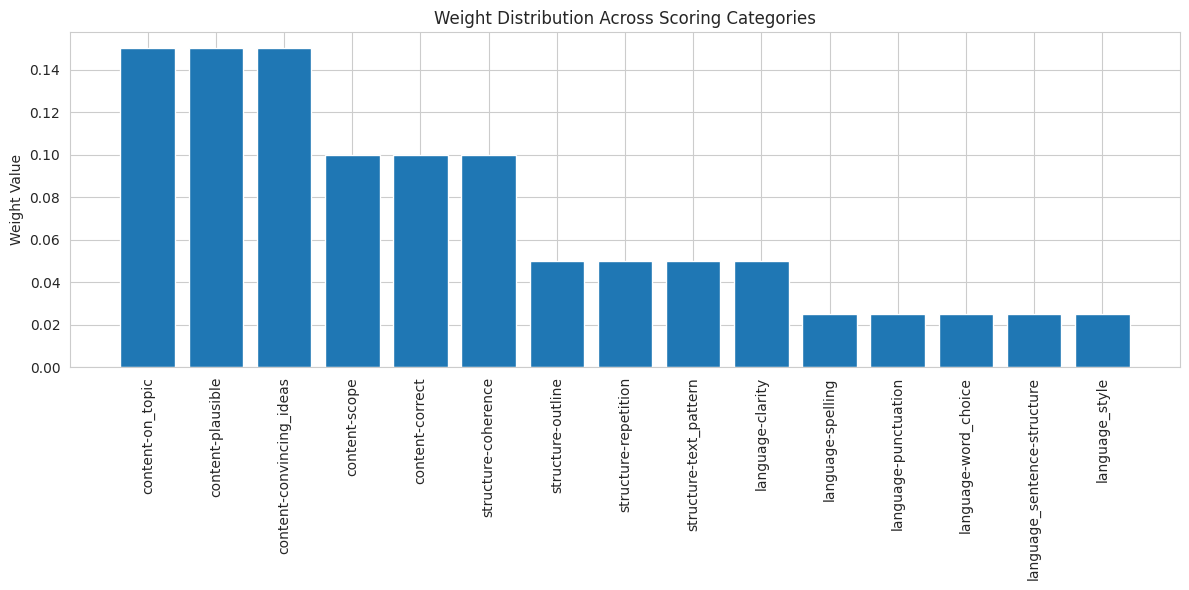

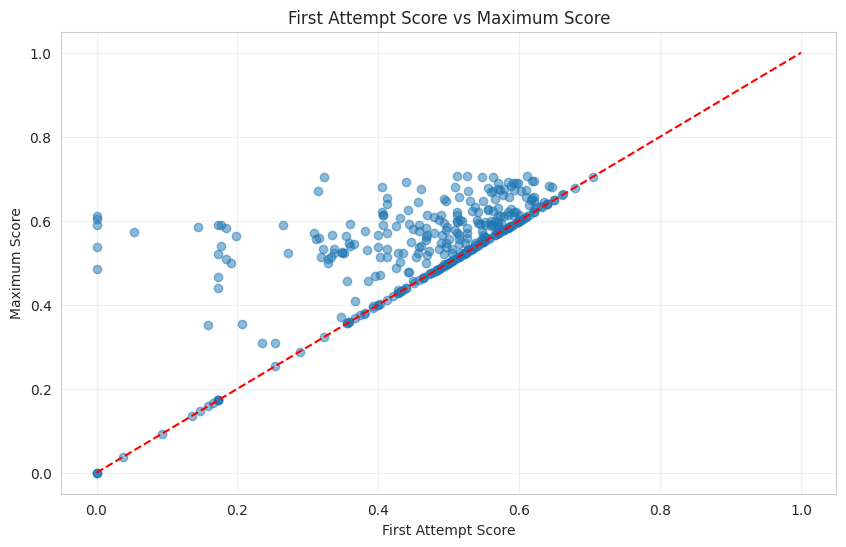

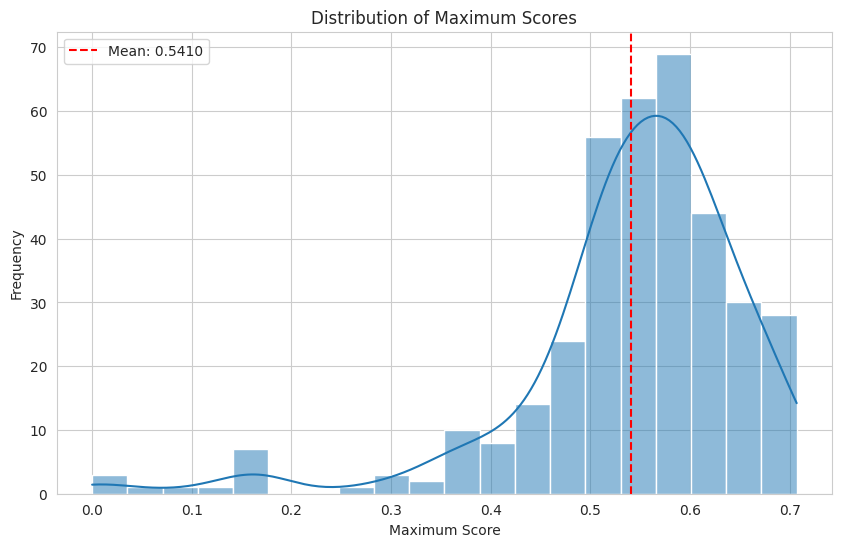

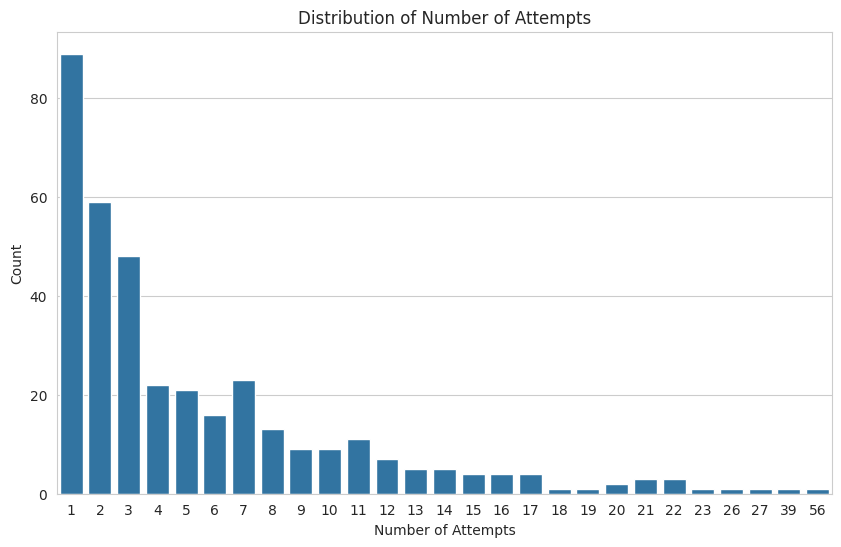

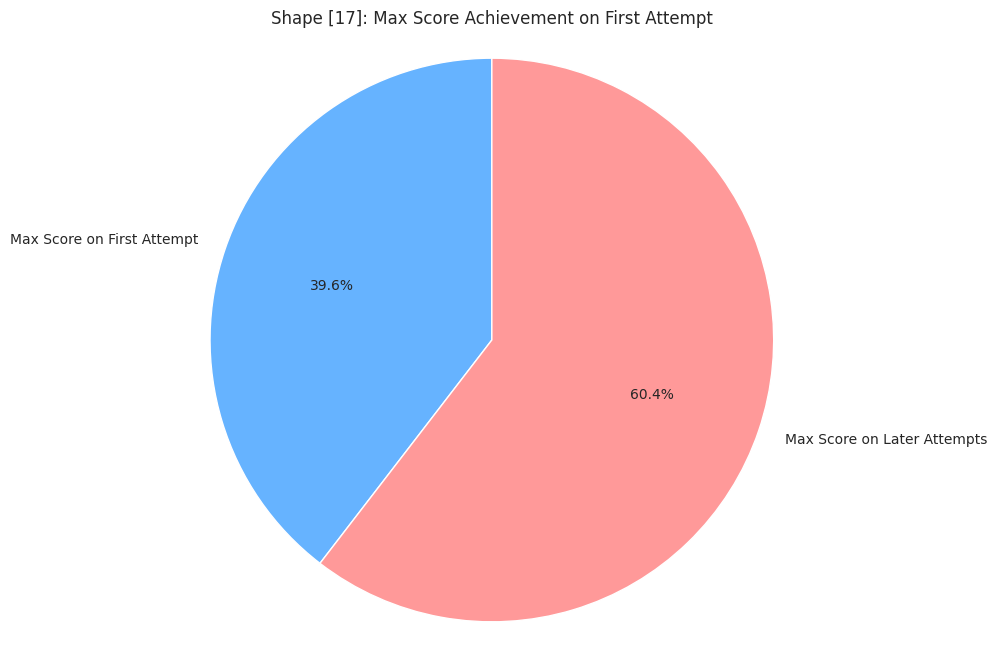

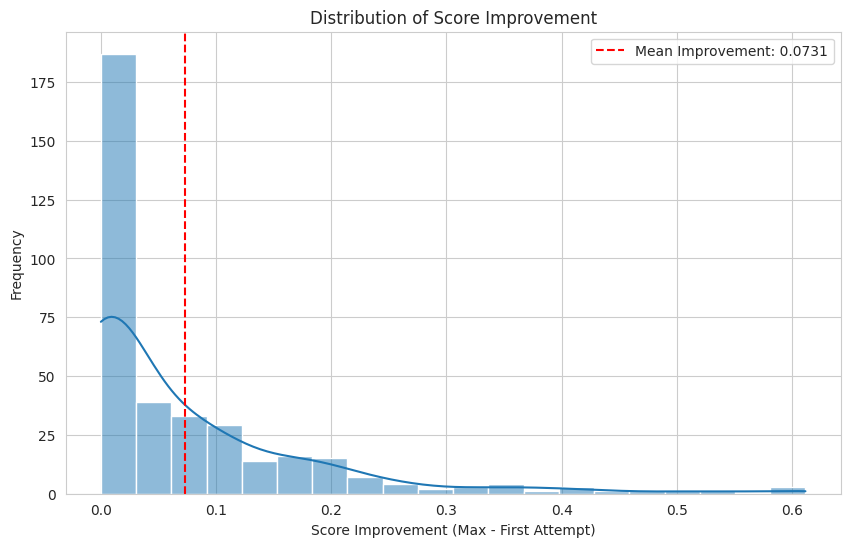


Visualization complete. Six charts have been created:
1. Weight distribution across scoring categories
2. First attempt score vs maximum score
3. Distribution of maximum scores
4. Distribution of number of attempts
5. Shape [17]: Max score achievement on first attempt (pie chart)
6. Distribution of score improvement


In [32]:
# ----- VISUALIZATION SECTION -----

# 1. Visualize the weights distribution
plt.figure(figsize=(12, 6))
plt.bar(weights.keys(), weights.values())
plt.xticks(rotation=90)
plt.title('Weight Distribution Across Scoring Categories')
plt.ylabel('Weight Value')
plt.tight_layout()
plt.show()

# 2. Visualize the first attempt vs max score
plt.figure(figsize=(10, 6))
plt.scatter(essay_max_score_df['first_attempt_score'], essay_max_score_df['max_score'], alpha=0.5)
plt.plot([0, 1], [0, 1], 'r--')  # Diagonal line where first attempt = max score
plt.xlabel('First Attempt Score')
plt.ylabel('Maximum Score')
plt.title('First Attempt Score vs Maximum Score')
plt.grid(True, alpha=0.3)
plt.show()

# 3. Visualize the distribution of maximum scores
plt.figure(figsize=(10, 6))
sns.histplot(essay_max_score_df['max_score'], bins=20, kde=True)
plt.title('Distribution of Maximum Scores')
plt.xlabel('Maximum Score')
plt.ylabel('Frequency')
plt.axvline(essay_max_score_df['max_score'].mean(), color='red', linestyle='--', label=f'Mean: {essay_max_score_df["max_score"].mean():.4f}')
plt.legend()
plt.show()

# 4. Visualize the number of attempts distribution
plt.figure(figsize=(10, 6))
sns.countplot(x='total_attempts', data=essay_max_score_df)
plt.title('Distribution of Number of Attempts')
plt.xlabel('Number of Attempts')
plt.ylabel('Count')
plt.show()

# 5. Pie chart for Shape [17] - Max score on first attempt
plt.figure(figsize=(8, 8))
labels = ['Max Score on First Attempt', 'Max Score on Later Attempts']
sizes = [
    essay_max_score_df['max_on_first_attempt'].sum(),
    len(essay_max_score_df) - essay_max_score_df['max_on_first_attempt'].sum()
]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#66b3ff', '#ff9999'])
plt.title('Shape [17]: Max Score Achievement on First Attempt')
plt.axis('equal')
plt.show()

# 6. Score improvement (max score - first attempt score)
essay_max_score_df['score_improvement'] = essay_max_score_df['max_score'] - essay_max_score_df['first_attempt_score']
plt.figure(figsize=(10, 6))
sns.histplot(essay_max_score_df['score_improvement'], bins=20, kde=True)
plt.title('Distribution of Score Improvement')
plt.xlabel('Score Improvement (Max - First Attempt)')
plt.ylabel('Frequency')
plt.axvline(essay_max_score_df['score_improvement'].mean(), color='red', linestyle='--', 
           label=f'Mean Improvement: {essay_max_score_df["score_improvement"].mean():.4f}')
plt.legend()
plt.show()

print("\nVisualization complete. Six charts have been created:")
print("1. Weight distribution across scoring categories")
print("2. First attempt score vs maximum score")
print("3. Distribution of maximum scores")
print("4. Distribution of number of attempts")
print("5. Shape [17]: Max score achievement on first attempt (pie chart)")
print("6. Distribution of score improvement")